# API Trade Data Exploration

This notebook demonstrates how to use the `TRADE_MAP_API` mapping to fetch, process, and visualize trade data from an API source.

In [ ]:
# 1. Import Required Libraries
import os
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from vacoda.mappings.trade_map import TRADE_MAP_API, standardize_trade_columns


## 2. Set Up TRADE_MAP_API Credentials

Store your API credentials securely. Here, we use environment variables for demonstration. Replace with your actual method as needed.

In [ ]:
# Set your API credentials (replace with your actual credentials or use a config file)
API_KEY = os.getenv('TRADE_API_KEY', 'your_api_key_here')
API_BASE_URL = 'https://api.example.com/trade'  # Replace with actual API endpoint

## 3. Test API Connection

Send a test request to verify your credentials and connection.

In [ ]:
# Test API connection (replace endpoint and params as needed)
response = requests.get(f"{API_BASE_URL}/ping", headers={"Authorization": f"Bearer {API_KEY}"})
if response.status_code == 200:
    print("API connection successful!")
else:
    print(f"API connection failed: {response.status_code}")

## 4. Fetch Trade Data Using TRADE_MAP_API

Fetch trade data for a specific country, product, or time period. Parse the JSON response into a pandas DataFrame.

In [ ]:
# Example: Fetch trade data (customize params as needed)
params = {
    "reporter": "840",  # USA
    "year": "2024",
    "flow": "1",        # Import
    # ... add more params as needed
}

response = requests.get(f"{API_BASE_URL}/data", headers={"Authorization": f"Bearer {API_KEY}"}, params=params)
data = response.json()

df_raw = pd.DataFrame(data["results"]) if "results" in data else pd.DataFrame(data)
print(f"Raw data shape: {df_raw.shape}")
df_raw.head()

In [ ]:
# Standardize columns using TRADE_MAP_API
if not df_raw.empty:
    df = standardize_trade_columns(df_raw, source_type="api")
    print(f"Standardized columns: {df.columns.tolist()}")
    df.head()
else:
    print("No data returned from API.")

## 5. Load Downloaded API CSV and Perform EDA

Load your already-downloaded API CSV file, standardize columns, and perform exploratory data analysis (EDA).

In [5]:
import pandas as pd
# Path to your downloaded API CSV file
csv_path = '../data/raw/api/Comtrade_hs_441012_trade.csv'  # Update path as needed

# Load the CSV
df_api = pd.read_csv(csv_path)
print(f"Loaded shape: {df_api.shape}")
df_api.head()

Loaded shape: (26097, 47)


,TypeCode,FreqCode,RefPeriodId,RefYear,RefMonth,Period,ReporterCode,ReporterISO,ReporterDesc,FlowCode,...,NetWgt,IsNetWgtEstimated,GrossWgt,IsGrossWgtEstimated,Cifvalue,Fobvalue,PrimaryValue,LegacyEstimationFlag,IsReported,IsAggregate
0,C,A,20140101,2014,52,2014,8,ALB,Albania,M,...,151953.0,False,NaN,False,73102.00,NaN,73102.00,0,True,False
1,C,A,20140101,2014,52,2014,12,DZA,Algeria,M,...,735109.0,False,NaN,False,397168.00,NaN,397168.00,0,True,False
2,C,A,20140101,2014,52,2014,24,AGO,Angola,M,...,291819.0,False,NaN,False,351573.00,NaN,351573.00,0,True,False
3,C,A,20140101,2014,52,2014,31,AZE,Azerbaijan,M,...,196191.0,False,NaN,False,130391.00,NaN,130391.00,0,True,False
4,C,A,20140101,2014,52,2014,32,ARG,Argentina,M,...,13909211.7,False,NaN,False,7463391.56,6547109.55,7463391.56,0,False,True


In [4]:
# Standardize columns using TRADE_MAP_API
from vacoda.mappings.trade_map import TRADE_MAP_API, standardize_trade_columns
if not df_api.empty:
    df = standardize_trade_columns(df_api, source_type="api")
    print(f"Standardized columns: {df.columns.tolist()}")
    df.head()
else:
    print("No data in CSV file.")

Standardized columns: ['type_code', 'freq_code', 'ref_period_id', 'year', 'month', 'period', 'reporter_code', 'reporter_iso', 'reporter_desc', 'flow_code', 'flow_desc', 'partner_code', 'partner_iso', 'partner_desc', 'partner2_code', 'partner2_iso', 'partner2_desc', 'hs_code_short', 'hs_code_search', 'is_original_classification', 'commodity_code', 'commodity_desc', 'aggregation_level', 'is_leaf', 'custom_code', 'custom_desc', 'MosCode', 'MotCode', 'MotDesc', 'quantity_unit_code', 'quantity_unit_abbr', 'quantity', 'is_quantity_estimated', 'alt_quantity_unit_code', 'alt_quantity_unit_abbr', 'alt_quantity', 'is_alt_quantity_estimated', 'NetWgt', 'is_netweight_estimated', 'GrossWgt', 'is_grossweight_estimated', 'Cifvalue', 'Fobvalue', 'value_usd_raw', 'legacy_estimation_flag', 'is_reported', 'is_aggregate']


In [ ]:
# EDA: Overview
print(df.info())
display(df.describe(include='all', datetime_is_numeric=True))
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nUnique values per column:")
print(df.nunique())

In [ ]:
# EDA: Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Example: Distribution of trade values
if 'value_usd' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df['value_usd'].dropna(), bins=50, kde=True)
    plt.title('Distribution of Trade Value (USD)')
    plt.xlabel('Trade Value (USD)')
    plt.ylabel('Frequency')
    plt.show()

# Example: Top 10 trading partners (if partner_code or partner_desc exists)
partner_col = 'partner_code' if 'partner_code' in df.columns else ('partner_desc' if 'partner_desc' in df.columns else None)
if partner_col:
    top_partners = df[partner_col].value_counts().head(10)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=top_partners.values, y=top_partners.index)
    plt.title('Top 10 Trading Partners')
    plt.xlabel('Number of Records')
    plt.ylabel('Partner')
    plt.show()

## Define and Use Global Constants for EDA

Store important or constant values as global variables for clarity and reuse in your analysis.

In [12]:
# Define global variables/constants for EDA
REQUIRED_COLUMNS = ['CmdCode', 'CmdDesc']
COMMODITY_CODE = df_api['CmdCode'].unique()
COMMODITY_DESC = df_api['CmdDesc'].unique()

print(f"Unique commodity codes: {COMMODITY_CODE}")
print(f"Unique commodity descriptions: {COMMODITY_DESC}")

Unique commodity codes: [441012]
Unique commodity descriptions: <ArrowStringArray>
['Oriented strand board (OSB) of wood, whether or not agglomerated with resins or other organic binding substances']
Length: 1, dtype: str


## Delete Constant columns

In [11]:
## Lets find the constant columns in the API data
constant_columns = [col for col in df_api.columns if df_api[col].nunique() == 1]
print(f"Constant columns in API data: {constant_columns}")

Constant columns in API data: ['TypeCode', 'FreqCode', 'RefMonth', 'PartnerCode', 'PartnerISO', 'PartnerDesc', 'ClassificationSearchCode', 'IsOriginalClassification', 'CmdCode', 'CmdDesc', 'aggrLevel', 'IsLeaf', 'MosCode', 'IsGrossWgtEstimated']


In [14]:
## Lets define a dataframe without constant columns
df = df_api.drop(columns=constant_columns)
print(f"Shape of dataframe without constant columns: {df.shape}")

Shape of dataframe without constant columns: (26097, 33)


## Further EDA: Commodity Analysis and Data Quality Checks

Explore the distribution, missingness, and relationships of key commodity fields in your API data.

In [15]:
# 1. Check for missing values in key columns
for col in REQUIRED_COLUMNS:
    missing = df[col].isnull().sum()
    print(f"Missing values in {col}: {missing}")

Missing values in CmdCode: 0
Missing values in CmdDesc: 0


In [ ]:
# 2. Frequency of each commodity code
top_commodities = df_api['CmdCode'].value_counts().head(10)
print("Top 10 commodity codes:")
print(top_commodities)

In [16]:
# 3. Distribution of trade value by commodity (if Value or value_usd exists)
value_col = 'Value' if 'Value' in df_api.columns else ('value_usd' if 'value_usd' in df_api.columns else None)
if value_col:
    import matplotlib.pyplot as plt
    import seaborn as sns
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='CmdCode', y=value_col, data=df_api[df_api['CmdCode'].isin(top_commodities.index)])
    plt.title('Trade Value Distribution for Top 10 Commodities')
    plt.xlabel('Commodity Code')
    plt.ylabel('Trade Value')
    plt.xticks(rotation=45)
    plt.show()
else:
    print('No trade value column found for distribution plot.')

No trade value column found for distribution plot.


In [ ]:
# 4. Cross-tabulation: Commodity vs. Partner (if partner column exists)
partner_col = 'PartnerCode' if 'PartnerCode' in df_api.columns else ('partner_code' if 'partner_code' in df_api.columns else None)
if partner_col:
    crosstab = pd.crosstab(df_api['CmdCode'], df_api[partner_col])
    print('Commodity vs. Partner cross-tabulation (top 5 rows):')
    display(crosstab.head())
else:
    print('No partner column found for cross-tabulation.')

## Focused EDA: NetWeight and Related Features

Analyze the distribution, missingness, and relationships of netweight and related columns in your API data.

In [30]:
df.columns.to_list()

['RefPeriodId',
 'RefYear',
 'Period',
 'ReporterCode',
 'ReporterISO',
 'ReporterDesc',
 'FlowCode',
 'FlowDesc',
 'Partner2Code',
 'Partner2ISO',
 'Partner2Desc',
 'ClassificationCode',
 'CustomsCode',
 'CustomsDesc',
 'MotCode',
 'MotDesc',
 'QtyUnitCode',
 'QtyUnitAbbr',
 'Qty',
 'IsQtyEstimated',
 'AltQtyUnitCode',
 'AltQtyUnitAbbr',
 'AltQty',
 'IsAltQtyEstimated',
 'NetWgt',
 'IsNetWgtEstimated',
 'GrossWgt',
 'Cifvalue',
 'Fobvalue',
 'PrimaryValue',
 'LegacyEstimationFlag',
 'IsReported',
 'IsAggregate']

## Unit Diagnostics

In [42]:
weight_related_cols = [col for col in df.columns if ('wgt' in col.lower() or 'qty' in col.lower())]
df[weight_related_cols].head(10)


,QtyUnitCode,QtyUnitAbbr,Qty,IsQtyEstimated,AltQtyUnitCode,AltQtyUnitAbbr,AltQty,IsAltQtyEstimated,NetWgt,IsNetWgtEstimated,GrossWgt
0,8,kg,1.519530e+05,False,-1,NaN,NaN,False,1.519530e+05,False,NaN
1,8,kg,7.351090e+05,False,-1,NaN,NaN,False,7.351090e+05,False,NaN
2,8,kg,2.918190e+05,False,-1,NaN,NaN,False,2.918190e+05,False,NaN
3,8,kg,1.961910e+05,False,-1,NaN,NaN,False,1.961910e+05,False,NaN
4,8,kg,1.390921e+07,False,8,kg,1.390921e+07,False,1.390921e+07,False,NaN
5,8,kg,1.831630e+03,False,8,kg,1.831630e+03,False,1.831630e+03,False,NaN
6,8,kg,1.420752e+07,True,-1,NaN,NaN,False,1.420752e+07,True,NaN
7,8,kg,1.005475e+08,False,8,kg,1.005475e+08,False,1.005475e+08,False,0.0
8,8,kg,4.545324e+06,False,8,kg,4.545324e+06,False,4.545324e+06,False,0.0
9,8,kg,1.364000e+03,False,-1,NaN,NaN,False,1.364000e+03,False,NaN


## Weight Diagnostics

In [45]:
# 1. Check for netweight-related columns
weight_cols = [col for col in df.columns if ('wgt' in col.lower() or 'qty' in col.lower()) and "unit" not in col.lower() and df[col].dtype in ['float64', 'int64']]
print(f"Weight-related columns: {weight_cols}")

Weight-related columns: ['Qty', 'AltQty', 'NetWgt', 'GrossWgt']


In [46]:
df[weight_cols].head()

,Qty,AltQty,NetWgt,GrossWgt
0,151953.0,NaN,151953.0,NaN
1,735109.0,NaN,735109.0,NaN
2,291819.0,NaN,291819.0,NaN
3,196191.0,NaN,196191.0,NaN
4,13909211.7,13909211.7,13909211.7,NaN


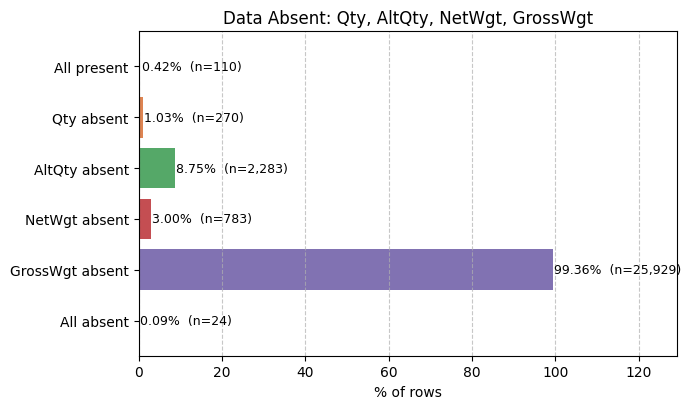

In [40]:
from vacoda.visualization.distributions import plot_data_coverage_bar
plot_data_coverage_bar(df, cols=netweight_cols)

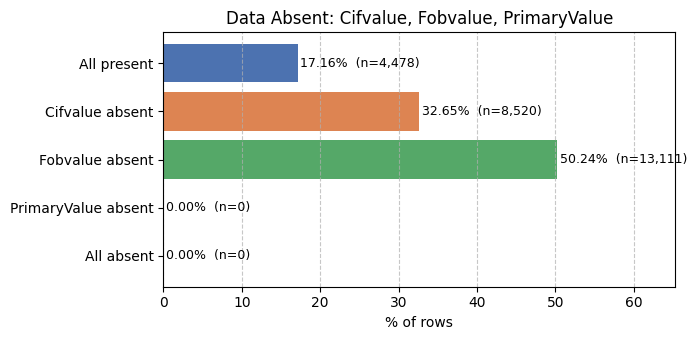

In [29]:
plot_data_coverage_bar(df, cols=[ 'Cifvalue',
 'Fobvalue',
 'PrimaryValue',])

## NetWeight Recovery

In [44]:
weight_related_cols

['QtyUnitCode',
 'QtyUnitAbbr',
 'Qty',
 'IsQtyEstimated',
 'AltQtyUnitCode',
 'AltQtyUnitAbbr',
 'AltQty',
 'IsAltQtyEstimated',
 'NetWgt',
 'IsNetWgtEstimated',
 'GrossWgt']

In [57]:
df[weight_related_cols].head(3)

,QtyUnitCode,QtyUnitAbbr,Qty,IsQtyEstimated,AltQtyUnitCode,AltQtyUnitAbbr,AltQty,IsAltQtyEstimated,NetWgt,IsNetWgtEstimated,GrossWgt
0,8,kg,151953.0,False,-1,NaN,NaN,False,151953.0,False,NaN
1,8,kg,735109.0,False,-1,NaN,NaN,False,735109.0,False,NaN
2,8,kg,291819.0,False,-1,NaN,NaN,False,291819.0,False,NaN


In [47]:
weight_cols

['Qty', 'AltQty', 'NetWgt', 'GrossWgt']

In [58]:
### Recovery from Quantity and Unit
pretty_print_series(assess_weight_recoverability(
   df, 
    weight_col = 'NetWgt',
    sup_col = 'AltQty',
    unit_col = 'AltQtyUnitCode',
    weight_unit_code = 8,
))

total_rows                                    26,097.00
missing_weight_percentage_total               3.00%
missing_weight_n                              783.00
recoverable_direct_percentage_total           0.54%
recoverable_direct_n                          141.00
potentially_recoverable_nonkg_percentage_total 2.09%
potentially_recoverable_nonkg_n               546.00
recoverable_direct_percentage_of_missing      18.01%
potentially_recoverable_nonkg_percentage_of_missing 69.73%
unresolved_n                                  96.00
unresolved_percentage_of_missing              12.26%


In [59]:
### Recovery from Quantity and Unit
from vacoda.utils.display import pretty_print_series
from vacoda.utils.diagnostics import assess_weight_recoverability
pretty_print_series(assess_weight_recoverability(
   df, 
    weight_col = 'NetWgt',
    sup_col = 'Qty',
    unit_col = 'QtyUnitCode',
    weight_unit_code = 8,
))

NameError: name 'pd' is not defined

## Value Recovery

In [77]:
df['PrimaryValue'].describe()

count    2.609700e+04
mean     9.150748e+06
std      9.059986e+07
min      2.300000e-01
25%      8.984353e+03
50%      7.749009e+04
75%      9.671321e+05
max      4.096566e+09
Name: PrimaryValue, dtype: float64

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Distribution of PrimaryValue'}, xlabel='PrimaryValue', ylabel='Count'>)

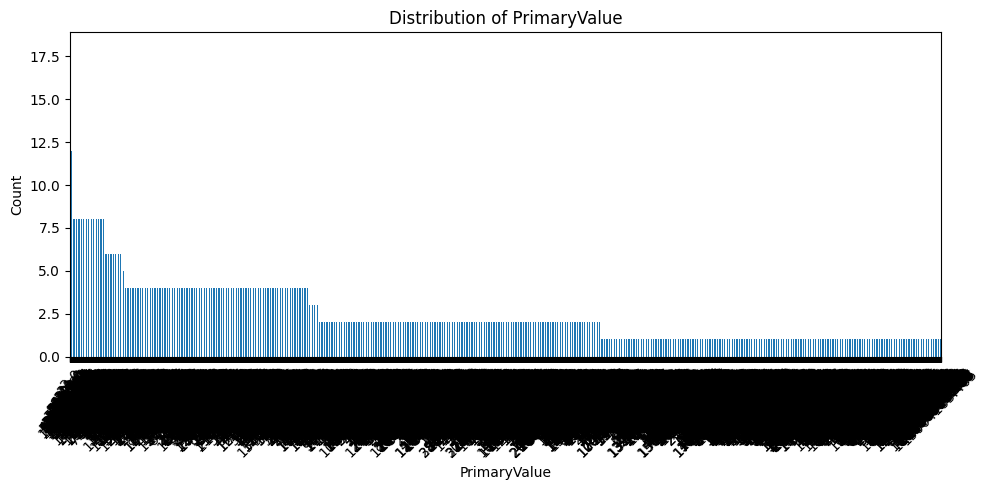

In [80]:
from vacoda.visualization.distributions import plot_bar_distribution
plot_bar_distribution(df, 'PrimaryValue')

In [83]:
df[df['PrimaryValue']<=0]

,RefPeriodId,RefYear,Period,ReporterCode,ReporterISO,ReporterDesc,FlowCode,FlowDesc,Partner2Code,Partner2ISO,...,IsAltQtyEstimated,NetWgt,IsNetWgtEstimated,GrossWgt,Cifvalue,Fobvalue,PrimaryValue,LegacyEstimationFlag,IsReported,IsAggregate


Shape of original dataframe: (26097, 33)
Shape after removing non-positive values: (26097,)


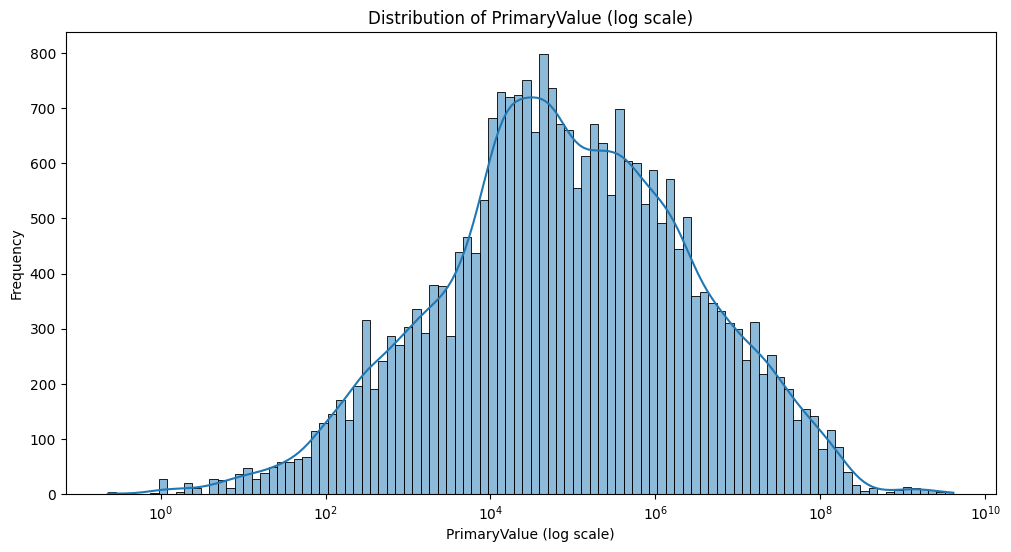

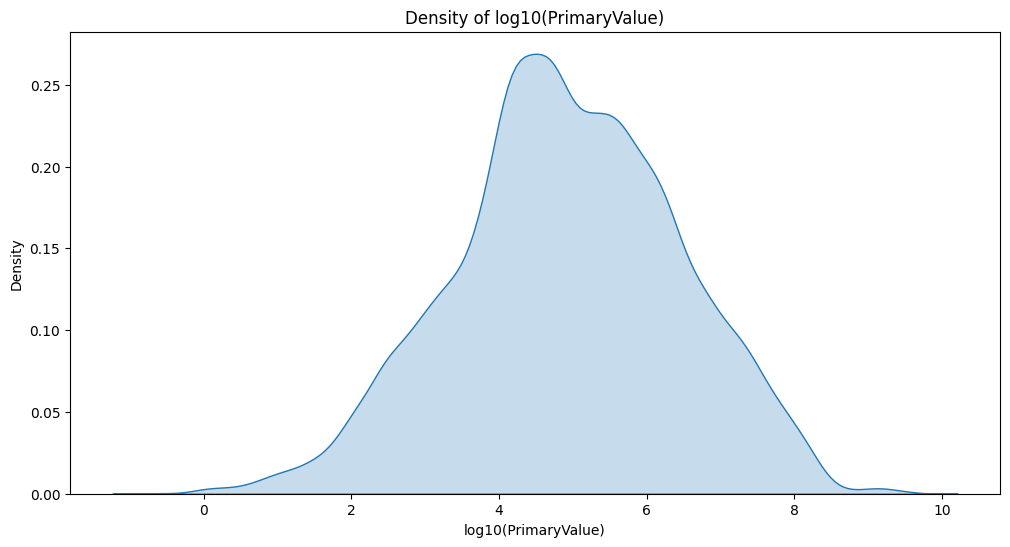

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Remove non-positive values for log scale
print(f"Shape of original dataframe: {df.shape}")
vals = df['PrimaryValue'].dropna()
vals = vals[vals > 0]
print(f"Shape after removing non-positive values: {vals.shape}")

plt.figure(figsize=(12, 6))
sns.histplot(vals, bins=100, kde=True, log_scale=(True, False))
plt.title('Distribution of PrimaryValue (log scale)')
plt.xlabel('PrimaryValue (log scale)')
plt.ylabel('Frequency')
plt.show()

# KDE only (for density)
plt.figure(figsize=(12, 6))
sns.kdeplot(np.log10(vals), fill=True)
plt.title('Density of log10(PrimaryValue)')
plt.xlabel('log10(PrimaryValue)')
plt.ylabel('Density')
plt.show()

In [60]:
df.columns.to_list()

['RefPeriodId',
 'RefYear',
 'Period',
 'ReporterCode',
 'ReporterISO',
 'ReporterDesc',
 'FlowCode',
 'FlowDesc',
 'Partner2Code',
 'Partner2ISO',
 'Partner2Desc',
 'ClassificationCode',
 'CustomsCode',
 'CustomsDesc',
 'MotCode',
 'MotDesc',
 'QtyUnitCode',
 'QtyUnitAbbr',
 'Qty',
 'IsQtyEstimated',
 'AltQtyUnitCode',
 'AltQtyUnitAbbr',
 'AltQty',
 'IsAltQtyEstimated',
 'NetWgt',
 'IsNetWgtEstimated',
 'GrossWgt',
 'Cifvalue',
 'Fobvalue',
 'PrimaryValue',
 'LegacyEstimationFlag',
 'IsReported',
 'IsAggregate']

In [62]:
value_cols = [col for col in df.columns if ('value' in col.lower())]
print(f"Value-related columns: {value_cols}")

Value-related columns: ['Cifvalue', 'Fobvalue', 'PrimaryValue']


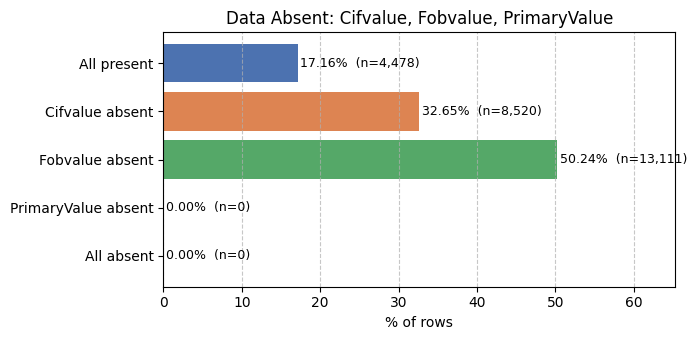

In [64]:
plot_data_coverage_bar(df, cols=value_cols)

In [72]:
def compute_feature_coverage(df: pd.DataFrame, feature: str) -> pd.Series:
    """
    Compute valid / missing count and percentage for a single column.
    Returns a Series with keys: total_rows, valid_n, valid_pct, missing_n, missing_pct
    """
    N = len(df)
    missing = df[feature].isna() | (df[feature] <= 0)
    missing_n = int(missing.sum())
    valid_n = N - missing_n
    return pd.Series({
        "feature_name": feature,
        "total_rows": N,
        "valid_n": valid_n,
        "valid_pct": valid_n / N * 100 if N > 0 else 0.0,
        "missing_n": missing_n,
        "missing_pct": missing_n / N * 100 if N > 0 else 0.0,
    })

def compute_features_coverage(df, features):
    """Return a DataFrame with coverage stats for each feature."""
    return pd.DataFrame({col: compute_feature_coverage(df, col) for col in features}).T

def log_feature_coverage(stats: pd.Series, feature_name: str = None) -> None:
    """Log the output of compute_feature_coverage in a human-readable format."""
    if feature_name:
        print(f"Coverage for {feature_name}:")
    print(f"  total_rows: {int(stats['total_rows']):,}")
    print(f"  valid rows: {int(stats['valid_n']):,} ({stats['valid_pct']:.2f}%)")
    print(f"  missing/nonpositive rows: {int(stats['missing_n']):,} ({stats['missing_pct']:.2f}%)")

def log_feature_coverage_old(stats: pd.Series, feature_name: str = None) -> None:
    """Log the output of compute_feature_coverage in a human-readable format."""
    prefix = f"{feature_name}: " if feature_name else ""
    print(f"{prefix}total_rows: {int(stats['total_rows']):,}")
    print(f"{prefix}valid rows: {int(stats['valid_n']):,} ({stats['valid_pct']:.2f}%)")
    print(f"{prefix}missing/nonpositive rows: {int(stats['missing_n']):,} ({stats['missing_pct']:.2f}%)")

def pretty_print_features_coverage(df_cov):
    """Nicely print the DataFrame returned by compute_features_coverage."""
    for feature, stats in df_cov.iterrows():
        log_feature_coverage(stats, feature)
        print("-" * 40)

In [76]:
features = ['NetWgt', 'PrimaryValue']
df_cov = compute_features_coverage(df, features)
log_feature_coverage(compute_feature_coverage(df, "NetWgt"), "Netweight")
log_feature_coverage(compute_feature_coverage(df, "PrimaryValue"), "Primary Value")

Coverage for Netweight:
  total_rows: 26,097
  valid rows: 25,314 (97.00%)
  missing/nonpositive rows: 783 (3.00%)
Coverage for Primary Value:
  total_rows: 26,097
  valid rows: 26,097 (100.00%)
  missing/nonpositive rows: 0 (0.00%)


In [68]:
features = ['NetWgt', 'PrimaryValue']
df_cov = compute_features_coverage(df, features)
pretty_print_features_coverage(df_cov)

NetWgt: total_rows: 26,097
NetWgt: valid rows: 25,314 (97.00%)
NetWgt: missing/nonpositive rows: 783 (3.00%)
----------------------------------------
PrimaryValue: total_rows: 26,097
PrimaryValue: valid rows: 26,097 (100.00%)
PrimaryValue: missing/nonpositive rows: 0 (0.00%)
----------------------------------------
